# Logistic Regression 

# Classification Algorithm

### Iris Dataset

### Objective: Predict Flower Species

In [2]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
data = pd.read_csv("Iris.csv")
data

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [7]:
data.columns

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

In [8]:
data = data[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species']]

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [10]:
data.isnull().sum()

SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [11]:
data.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [12]:
data["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [13]:
species_mapping = {"Iris-setosa":0,"Iris-versicolor":1,"Iris-virginica":2}
data["Species_encoded"] = data["Species"].map(species_mapping)

In [14]:
data

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Species_encoded
0,5.1,3.5,1.4,0.2,Iris-setosa,0
1,4.9,3.0,1.4,0.2,Iris-setosa,0
2,4.7,3.2,1.3,0.2,Iris-setosa,0
3,4.6,3.1,1.5,0.2,Iris-setosa,0
4,5.0,3.6,1.4,0.2,Iris-setosa,0
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica,2
146,6.3,2.5,5.0,1.9,Iris-virginica,2
147,6.5,3.0,5.2,2.0,Iris-virginica,2
148,6.2,3.4,5.4,2.3,Iris-virginica,2


In [15]:
X = data[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]
y = data["Species"]

In [16]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.30)

## Creating First Model: Logistic Regression

In [17]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression()
logreg.fit(X_train,y_train)
y_pred = logreg.predict(X_test)

In [20]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_test,y_pred))

0.9333333333333333


In [21]:
y_proba = logreg.predict_proba(X_test)
y_proba

array([[9.85917140e-01, 1.40827377e-02, 1.22619094e-07],
       [6.86419747e-03, 8.70996557e-01, 1.22139246e-01],
       [2.10702789e-03, 7.89718286e-01, 2.08174686e-01],
       [9.84890766e-01, 1.51090210e-02, 2.13473571e-07],
       [4.94200898e-05, 7.44268826e-02, 9.25523697e-01],
       [7.56381609e-04, 4.04748357e-01, 5.94495261e-01],
       [1.48574273e-04, 1.11817396e-01, 8.88034029e-01],
       [9.17465016e-06, 4.71174666e-02, 9.52873359e-01],
       [2.49659203e-03, 3.16653825e-01, 6.80849583e-01],
       [9.32922942e-01, 6.70764946e-02, 5.63617515e-07],
       [3.85271905e-03, 7.84871301e-01, 2.11275980e-01],
       [9.59516194e-01, 4.04831431e-02, 6.62616378e-07],
       [7.55873911e-04, 3.57817699e-01, 6.41426427e-01],
       [5.77123037e-04, 3.03041448e-01, 6.96381429e-01],
       [1.03903357e-02, 8.88516960e-01, 1.01092704e-01],
       [9.49066803e-01, 5.09324460e-02, 7.50534316e-07],
       [7.24634206e-06, 1.20759446e-02, 9.87916809e-01],
       [9.79965378e-01, 2.00344

In [22]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        16
Iris-versicolor       1.00      0.81      0.90        16
 Iris-virginica       0.81      1.00      0.90        13

       accuracy                           0.93        45
      macro avg       0.94      0.94      0.93        45
   weighted avg       0.95      0.93      0.93        45



In [23]:
from sklearn.metrics import confusion_matrix

In [24]:
cm = confusion_matrix(y_test,y_pred)
cm

array([[16,  0,  0],
       [ 0, 13,  3],
       [ 0,  0, 13]])

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

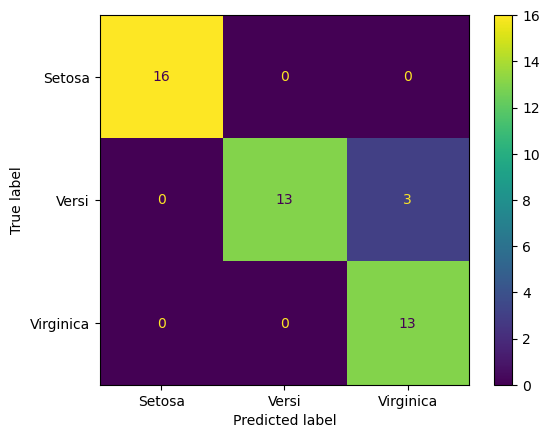

In [26]:
disp = ConfusionMatrixDisplay(cm,display_labels=["Setosa","Versi","Virginica"])
disp.plot()
plt.show()

In [28]:
from sklearn.metrics import roc_auc_score
roc_auc = roc_auc_score(y_test,y_proba,multi_class="ovr")
roc_auc

np.float64(0.9924016357206012)